# Train/Test Split e Test Set

Este notebook aplica a divisão clássica do conjunto em treino e teste para avaliar um modelo em dados nunca vistos antes.

Regra do problema:
- alta qualidade: quality >= 7
- baixa/média qualidade: quality < 7


Tamanho treino: 914
Tamanho teste: 229
Proporção da classe positiva em treino: 0.1389
Proporção da classe positiva em teste: 0.1397


/tmp/ipykernel_165654/661327160.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_summary, x='conjunto', y='n_amostras', palette='viridis')


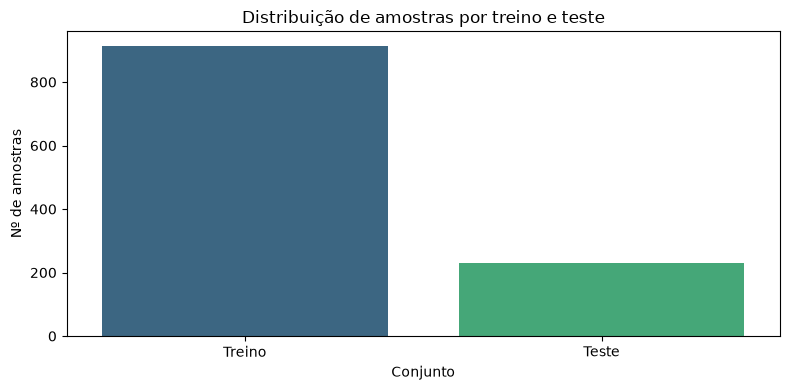

/tmp/ipykernel_165654/661327160.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_summary, x='conjunto', y='classe_positiva', palette='magma')


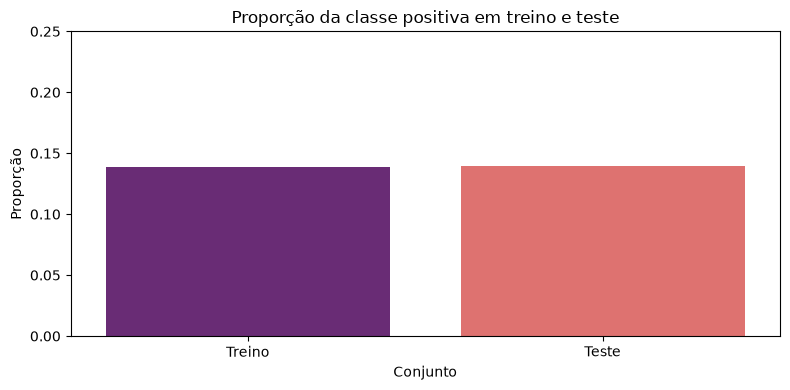

In [3]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

wine = pd.read_csv("../data/WineQT.csv")
wine["target"] = (wine["quality"] >= 7).astype(int)
X = wine[[c for c in wine.columns if c not in {"quality", "target", "Id"}]]
y = wine["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tamanho treino: {len(X_train)}")
print(f"Tamanho teste: {len(X_test)}")
print(f"Proporção da classe positiva em treino: {y_train.mean():.4f}")
print(f"Proporção da classe positiva em teste: {y_test.mean():.4f}")

import matplotlib.pyplot as plt
import seaborn as sns

split_summary = pd.DataFrame(
    {
        "conjunto": ["Treino", "Teste"],
        "n_amostras": [len(X_train), len(X_test)],
        "classe_positiva": [y_train.mean(), y_test.mean()],
    }
)

plt.figure(figsize=(8, 4))
sns.barplot(data=split_summary, x="conjunto", y="n_amostras", palette="viridis")
plt.title("Distribuição de amostras por treino e teste")
plt.xlabel("Conjunto")
plt.ylabel("Nº de amostras")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=split_summary, x="conjunto", y="classe_positiva", palette="magma")
plt.title("Proporção da classe positiva em treino e teste")
plt.xlabel("Conjunto")
plt.ylabel("Proporção")
plt.ylim(0, 0.25)
plt.tight_layout()
plt.show()

In [4]:
models = {
    "logreg_balanced": LogisticRegression(
        max_iter=4000, class_weight="balanced", random_state=42
    ),
    "decision_tree": DecisionTreeClassifier(
        max_depth=4, random_state=42, class_weight="balanced"
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print("\nModelo:", name)
    print("accuracy=", round(accuracy_score(y_test, pred), 4))
    print("precision=", round(precision_score(y_test, pred, zero_division=0), 4))
    print("recall=", round(recall_score(y_test, pred, zero_division=0), 4))
    print("f1=", round(f1_score(y_test, pred, zero_division=0), 4))
    print("roc_auc=", round(roc_auc_score(y_test, proba), 4))


Modelo: logreg_balanced
accuracy= 0.7948
precision= 0.3729
recall= 0.6875
f1= 0.4835
roc_auc= 0.8384

Modelo: decision_tree
accuracy= 0.8079
precision= 0.3846
recall= 0.625
f1= 0.4762
roc_auc= 0.8269


# Observações de negócio
#
# O conjunto de teste é fundamental para verificar generalização e evitar overfitting.
# Como a classe positiva é minoritária, métricas isoladas como acurácia podem ser enganosas.
# O uso combinado de precision, recall, F1 e ROC-AUC é mais apropriado para esta decisão.
